In [5]:

import pandas as pd

# Loading training & testing datasets
train = pd.read_csv('/content/kathmandu_weather_train_orignal.csv')
test = pd.read_csv('/content/kathmandu_weather_test_orignal.csv')

# Checking dataset size
print("Training data shape:", train.shape)
print("Testing data shape:", test.shape)

# Display first 5 rows
display(train.head())


Training data shape: (26304, 9)
Testing data shape: (8760, 9)


,time,temperature_2m,dew_point_2m,cloud_cover,weather_code,precipitation,hour,month,us_aqi
0,2022-10-01 00:00:00,17.2,16.9,21,1,0.0,0,10,80.0
1,2022-10-01 01:00:00,17.3,16.9,9,0,0.0,1,10,81.0
2,2022-10-01 02:00:00,17.1,16.7,14,0,0.0,2,10,82.0
3,2022-10-01 03:00:00,16.8,16.4,6,0,0.0,3,10,83.0
4,2022-10-01 04:00:00,16.6,16.1,2,0,0.0,4,10,84.0


In [6]:

# Check data types
print("DATA TYPES:")
print(train.dtypes)

# Check missing values
print("\nMISSING VALUES:")
print(train.isnull().sum())

# Check duplicate rows
print("\nDUPLICATES:")
print("Training:", train.duplicated().sum())
print("Testing:", test.duplicated().sum())

# Check statistical summary
print("\nSTATISTICAL SUMMARY:")
display(train.describe())


DATA TYPES:
time               object
temperature_2m    float64
dew_point_2m      float64
cloud_cover         int64
weather_code        int64
precipitation     float64
hour                int64
month               int64
us_aqi            float64
dtype: object

MISSING VALUES:
time              0
temperature_2m    0
dew_point_2m      0
cloud_cover       0
weather_code      0
precipitation     0
hour              0
month             0
us_aqi            0
dtype: int64

DUPLICATES:
Training: 0
Testing: 0

STATISTICAL SUMMARY:


,temperature_2m,dew_point_2m,cloud_cover,weather_code,precipitation,hour,month,us_aqi
count,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000
mean,18.169058,13.010265,47.799536,13.411002,0.259443,11.500000,6.521898,102.213732
std,5.788889,6.596971,42.105011,22.491178,1.141840,6.922318,3.449052,35.396445
min,0.800000,-6.700000,0.000000,0.000000,0.000000,0.000000,1.000000,12.000000
25%,14.000000,7.400000,2.000000,0.000000,0.000000,5.750000,4.000000,73.000000
50%,19.200000,12.900000,39.000000,1.000000,0.000000,11.500000,7.000000,95.000000
75%,22.200000,19.800000,99.000000,3.000000,0.000000,17.250000,10.000000,130.000000
max,31.700000,23.200000,100.000000,65.000000,24.300000,23.000000,12.000000,208.000000


In [7]:

# Convert time column to datetime format
train['time'] = pd.to_datetime(train['time'])
test['time'] = pd.to_datetime(test['time'])

# Check the result
print("Training time type:", train['time'].dtype)
print("Testing time type:", test['time'].dtype)

# Check date ranges
print("Training period:", train['time'].min(), "to", train['time'].max())
print("Testing period:", test['time'].min(), "to", test['time'].max())


Training time type: datetime64[ns]
Testing time type: datetime64[ns]
Training period: 2022-10-01 00:00:00 to 2025-09-30 23:00:00
Testing period: 2025-10-01 00:00:00 to 2026-09-30 23:00:00


In [8]:

# Select the six features required
features = [
    'temperature_2m',
    'dew_point_2m',
    'cloud_cover',
    'precipitation',
    'hour',
    'month'
]

# Creating feature datasets
X_train = train[features].copy()
X_test = test[features].copy()

# Keeping actual AQI values separately for later analysis
y_train = train['us_aqi'].copy()
y_test = test['us_aqi'].copy()

# Display selected features
print("Selected features:")
print(features)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

display(X_train.head())


Selected features:
['temperature_2m', 'dew_point_2m', 'cloud_cover', 'precipitation', 'hour', 'month']

Training feature shape: (26304, 6)
Testing feature shape: (8760, 6)


,temperature_2m,dew_point_2m,cloud_cover,precipitation,hour,month
0,17.2,16.9,21,0.0,0,10
1,17.3,16.9,9,0.0,1,10
2,17.1,16.7,14,0.0,2,10
3,16.8,16.4,6,0.0,3,10
4,16.6,16.1,2,0.0,4,10


In [9]:

from sklearn.preprocessing import StandardScaler

# scaling the features so they are on a similar scale
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# checking the scaled data
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nFirst 5 scaled rows:")
print(X_train_scaled[:5])


Training data shape: (26304, 6)
Testing data shape: (8760, 6)

First 5 scaled rows:
[[-0.16740284  0.58963563 -0.6365049  -0.22721948 -1.66132477  1.00844189]
 [-0.15012803  0.58963563 -0.92151203 -0.22721948 -1.51686175  1.00844189]
 [-0.18467764  0.55931812 -0.80275906 -0.22721948 -1.37239873  1.00844189]
 [-0.23650204  0.51384184 -0.99276381 -0.22721948 -1.2279357   1.00844189]
 [-0.27105164  0.46836556 -1.08776619 -0.22721948 -1.08347268  1.00844189]]


K = 2 | Inertia = 114105.91 | Silhouette = 0.2797
K = 3 | Inertia = 93823.94 | Silhouette = 0.3001
K = 4 | Inertia = 76668.57 | Silhouette = 0.3166
K = 5 | Inertia = 67124.91 | Silhouette = 0.2825
K = 6 | Inertia = 58668.81 | Silhouette = 0.2803
K = 7 | Inertia = 52570.12 | Silhouette = 0.2848
K = 8 | Inertia = 47813.80 | Silhouette = 0.2972
K = 9 | Inertia = 43986.95 | Silhouette = 0.3003
K = 10 | Inertia = 40299.75 | Silhouette = 0.3044


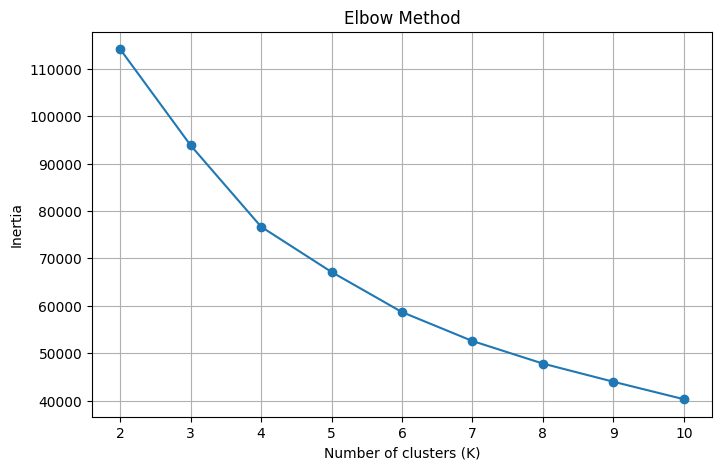

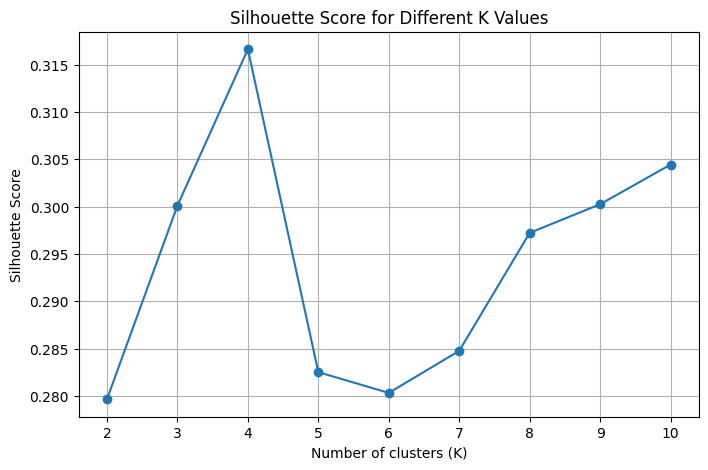

In [10]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# trying different numbers of clusters
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:
    # creating and fitting the model
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_train_scaled)

    # saving the scores
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(
            X_train_scaled,
            labels,
            sample_size=5000,
            random_state=42
        )
    )

# showing the scores for each k
for k, inertia, silhouette in zip(
    k_values, inertia_values, silhouette_values
):
    print(f"K = {k} | Inertia = {inertia:.2f} | Silhouette = {silhouette:.4f}")

# plotting the elbow graph
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid(True)
plt.show()

# plotting the silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_values, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')
plt.grid(True)
plt.show()


In [11]:

# creating our final k-means model with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# fitting the model on training data
train_clusters = kmeans.fit_predict(X_train_scaled)

# assigning clusters to testing data
test_clusters = kmeans.predict(X_test_scaled)

# finding the cluster centres
centres = scaler.inverse_transform(kmeans.cluster_centers_)

centres_df = pd.DataFrame(centres, columns=features)

print("Cluster centres:")
display(centres_df.round(2))

# checking the average AQI in each cluster
train['cluster'] = train_clusters

print("AQI by cluster:")
display(
    train.groupby('cluster')['us_aqi']
    .agg(['mean', 'min', 'max', 'count'])
    .round(2)
)


Cluster centres:


,temperature_2m,dew_point_2m,cloud_cover,precipitation,hour,month
0,14.05,9.22,21.10,0.01,11.51,11.22
1,14.96,6.90,23.77,0.02,11.33,2.61
2,22.18,18.89,75.49,0.30,11.60,7.25
3,22.74,20.37,97.00,8.03,11.92,7.40


AQI by cluster:


,mean,min,max,count
cluster,,,,
0,116.06,12.0,198.0,5294
1,118.71,55.0,208.0,8670
2,85.25,18.0,208.0,11956
3,66.90,18.0,152.0,384


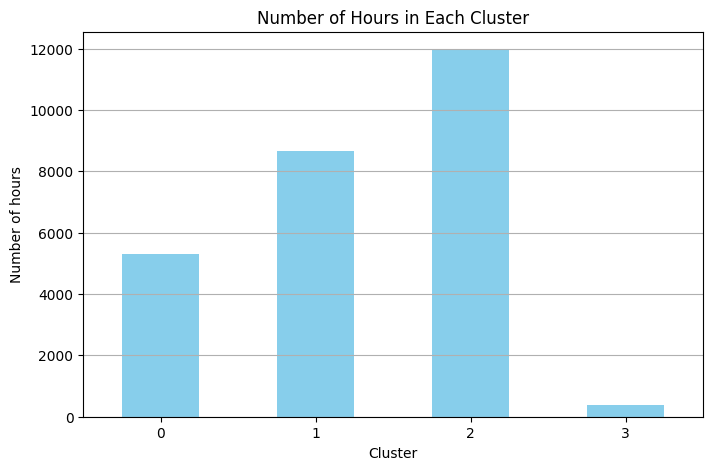

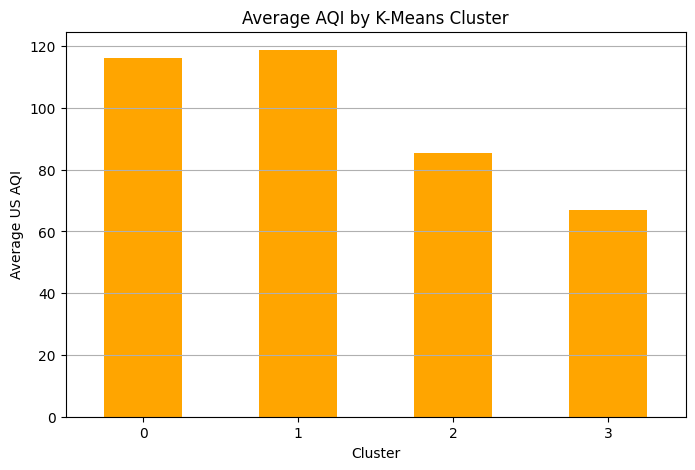

In [12]:

import matplotlib.pyplot as plt

# showing how many hours belong to each cluster
plt.figure(figsize=(8, 5))
train['cluster'].value_counts().sort_index().plot(
    kind='bar',
    color='skyblue'
)
plt.xlabel('Cluster')
plt.ylabel('Number of hours')
plt.title('Number of Hours in Each Cluster')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

# comparing average AQI between clusters
aqi_means = train.groupby('cluster')['us_aqi'].mean()

plt.figure(figsize=(8, 5))
aqi_means.plot(kind='bar', color='orange')
plt.xlabel('Cluster')
plt.ylabel('Average US AQI')
plt.title('Average AQI by K-Means Cluster')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


In [13]:

# adding the cluster results to testing data
test['cluster'] = test_clusters

# checking AQI for each cluster in testing data
print("Testing AQI by cluster:")

display(
    test.groupby('cluster')['us_aqi']
    .agg(['mean', 'min', 'max', 'count'])
    .round(2)
)

# showing the number of hours in each cluster
print("\nTesting cluster distribution:")
print(test['cluster'].value_counts().sort_index())


Testing AQI by cluster:


,mean,min,max,count
cluster,,,,
0,124.71,53.0,178.0,1754
1,144.54,58.0,217.0,2484
2,96.15,45.0,217.0,4402
3,75.08,45.0,157.0,120



Testing cluster distribution:
cluster
0    1754
1    2484
2    4402
3     120
Name: count, dtype: int64


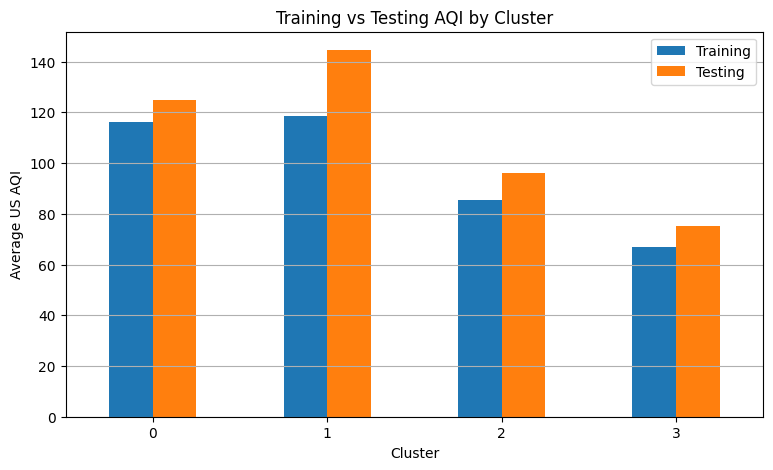

In [14]:

# comparing average AQI in training and testing data
train_aqi = train.groupby('cluster')['us_aqi'].mean()
test_aqi = test.groupby('cluster')['us_aqi'].mean()

comparison = pd.DataFrame({
    'Training': train_aqi,
    'Testing': test_aqi
})

comparison.plot(kind='bar', figsize=(9, 5))

plt.xlabel('Cluster')
plt.ylabel('Average US AQI')
plt.title('Training vs Testing AQI by Cluster')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()


In [15]:

# making a summary of our training results
train_summary = train.groupby('cluster')['us_aqi'].agg(
    ['mean', 'min', 'max', 'count']
).round(2)

# doing the same for testing results
test_summary = test.groupby('cluster')['us_aqi'].agg(
    ['mean', 'min', 'max', 'count']
).round(2)

print("Training results:")
display(train_summary)

print("Testing results:")
display(test_summary)

# saving the results for our report
train_summary.to_csv('kmeans_training_results.csv')
test_summary.to_csv('kmeans_testing_results.csv')
centres_df.to_csv('kmeans_cluster_centres.csv', index=False)

print("All three result files have been saved!")


Training results:


,mean,min,max,count
cluster,,,,
0,116.06,12.0,198.0,5294
1,118.71,55.0,208.0,8670
2,85.25,18.0,208.0,11956
3,66.90,18.0,152.0,384


Testing results:


,mean,min,max,count
cluster,,,,
0,124.71,53.0,178.0,1754
1,144.54,58.0,217.0,2484
2,96.15,45.0,217.0,4402
3,75.08,45.0,157.0,120


All three result files have been saved!


In [17]:

from google.colab import files

files.download('kmeans_training_results.csv')
files.download('kmeans_testing_results.csv')
files.download('kmeans_cluster_centres.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>